In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "id":                [3, 5, 6, 7, 8, 9],
    "name":              ["Linsensuppe", "Apfelstrudel", "Lachs-Pasta", "Burrito", "Curry", "Risotto"],
    "date_score":        [ 6.0, -2.0, 8.0,  4.0, 9.0, 1.0],
    "reward_score":      [ 5.5,  3.0, 6.2,  7.0, 4.8, 6.5],
    "damp_score_mult":   [ 1.0,  0.2, 1.0, 0.63, 1.0, 0.9],
    "damp_score_offset": [ 0.0,  2.0, -3.0, -5.0, 3.0, 0.0],
})
wishlist = {6, 9}          # IDs auf der Wunschliste

In [2]:
def wishlist_score(ids, wishlist):
    return np.where(np.isin(ids, list(wishlist)), 10, 0)

def total_score(date_score, reward_score, wish, mult, offset):
    return (date_score + reward_score + wish) * mult + offset + wish / 5

df["wishlist_score"] = wishlist_score(df["id"], wishlist)
df["score"] = total_score(df["date_score"], df["reward_score"], df["wishlist_score"],
                          df["damp_score_mult"], df["damp_score_offset"])
df

,id,name,date_score,reward_score,damp_score_mult,damp_score_offset,wishlist_score,score
0,3,Linsensuppe,6.0,5.5,1.00,0.0,0,11.50
1,5,Apfelstrudel,-2.0,3.0,0.20,2.0,0,2.20
2,6,Lachs-Pasta,8.0,6.2,1.00,-3.0,10,23.20
3,7,Burrito,4.0,7.0,0.63,-5.0,0,1.93
4,8,Curry,9.0,4.8,1.00,3.0,0,16.80
5,9,Risotto,1.0,6.5,0.90,0.0,10,17.75


In [3]:
def softmax(score, T=1.0):
    z = np.asarray(score, dtype=float) / T
    z -= z.max()                     # verhindert Überlauf bei großen Scores, Ergebnis bleibt gleich
    e = np.exp(z)
    return e / e.sum()

T = 3.0
df["p"] = softmax(df["score"], T)
df.sort_values("p", ascending=False)

,id,name,date_score,reward_score,damp_score_mult,damp_score_offset,wishlist_score,score,p
2,6,Lachs-Pasta,8.0,6.2,1.00,-3.0,10,23.20,0.767462
5,9,Risotto,1.0,6.5,0.90,0.0,10,17.75,0.124764
4,8,Curry,9.0,4.8,1.00,3.0,0,16.80,0.090900
0,3,Linsensuppe,6.0,5.5,1.00,0.0,0,11.50,0.015535
1,5,Apfelstrudel,-2.0,3.0,0.20,2.0,0,2.20,0.000700
3,7,Burrito,4.0,7.0,0.63,-5.0,0,1.93,0.000640


In [4]:
rng = np.random.default_rng()
choice = rng.choice(df["id"], p=df["p"])
df[df["id"] == choice]

,id,name,date_score,reward_score,damp_score_mult,damp_score_offset,wishlist_score,score,p
2,6,Lachs-Pasta,8.0,6.2,1.0,-3.0,10,23.2,0.767462


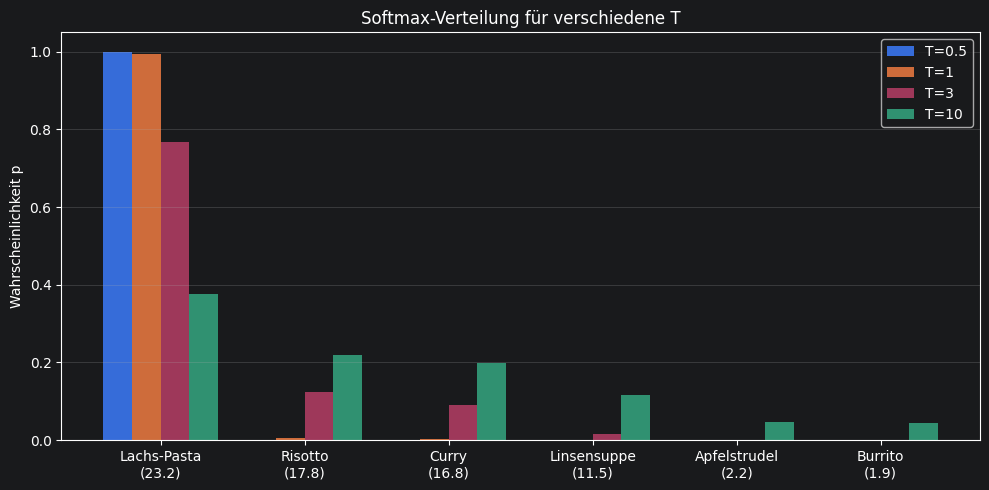

In [5]:
Ts = [0.5, 1, 3, 10]
order = df.sort_values("score", ascending=False)

x = np.arange(len(order))
w = 0.8 / len(Ts)

plt.figure(figsize=(10, 5))
for i, T in enumerate(Ts):
    plt.bar(x + i * w, softmax(order["score"], T), width=w, label=f"T={T}")
plt.xticks(x + w * (len(Ts) - 1) / 2, [f"{n}\n({s:.1f})" for n, s in zip(order["name"], order["score"])])
plt.ylabel("Wahrscheinlichkeit p")
plt.title("Softmax-Verteilung für verschiedene T")
plt.legend()
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

In [6]:
draws = rng.choice(df["id"], size=10_000, p=softmax(df["score"], T=3))
pd.Series(draws).value_counts(normalize=True).rename("gezogen").to_frame() \
  .join(df.set_index("id")[["name", "p"]])

,gezogen,name,p
6,0.7651,Lachs-Pasta,0.767462
9,0.1291,Risotto,0.124764
8,0.0882,Curry,0.090900
3,0.0161,Linsensuppe,0.015535
7,0.0012,Burrito,0.000640
5,0.0003,Apfelstrudel,0.000700
